<a href="https://colab.research.google.com/github/viktoriia1723/pattern-recognition-practice/blob/main/notebooks/PR02_Krashchenko_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 2
## Дослідницький аналіз і підготовка даних

**Дисципліна:** Розпізнавання образів і машинне навчання
**Студент:** Кращенко Вікторія
**Група:** ІН-32/2
**Дата виконання:** 06.11.2026

### Мета роботи
Навчитися аналізувати якість табличних даних, виявляти та виправляти пропуски, дублікати, неправильні типи й аномальні значення, кодувати категоріальні ознаки та формувати навчальну і тестову вибірки.

## Короткі теоретичні відомості

- **EDA** (дослідницький аналіз даних) — початкове вивчення структури таблиці, типів ознак, пропусків, дублікатів, розподілів, балансу класів, взаємозв'язків і аномалій.
- **Пропуски** (`NaN`, `None`, `pd.NA`): числові ознаки заповнюємо медіаною, категоріальні — модою; рядки без цільової змінної видаляємо.
- **Дублікати** спотворюють статистику та можуть потрапити одночасно в train і test, завищуючи оцінку якості.
- **Неправильні типи**: один текстовий запис робить весь стовпець типу `object`; виправляється `pd.to_numeric(errors="coerce")`.
- **Аномалії**: фізично неможливі значення (≤ 0) та значення за межами `[Q1 − 3·IQR; Q3 + 3·IQR]`.
- **One-hot-кодування** — для номінальних категорій без природного порядку.
- **Стратифікація** (`stratify=y`) зберігає частки класів у train і test.
- **Витік даних** — використання інформації, яка не повинна бути доступною моделі (наприклад, цільової змінної в X).

## 1. Підключення бібліотек
Підключаються бібліотеки для роботи з таблицями, числовими даними, візуалізацією, збереженням метаданих і формуванням train/test-вибірок.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Підключення Google Drive
Google Drive використовується для читання початкових даних і збереження результатів очищення.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"
X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"
SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Папка проєкту:", PROJECT_DIR)
print("Папка початкових даних:", DATA_DIR)
print("Папка підготовлених даних:", PROCESSED_DIR)
print("Папка звітів:", REPORTS_DIR)

Папка проєкту: /content/drive/MyDrive/pattern-recognition-practice
Папка початкових даних: /content/drive/MyDrive/pattern-recognition-practice/data
Папка підготовлених даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/reports


## 3. Завантаження початкового набору Iris
Спочатку перевіряється наявність файла `iris.csv`, створеного у практичній роботі 1. Якщо файл відсутній, він створюється повторно.

In [4]:
if SOURCE_PATH.exists():
    source_df = pd.read_csv(SOURCE_PATH)
    print("Початковий файл завантажено з Google Drive.")
else:
    print("Файл iris.csv не знайдено. Створюємо його повторно.")
    iris = load_iris(as_frame=True)
    source_df = iris.frame.copy()
    source_df["species"] = source_df["target"].map(
        {0: "setosa", 1: "versicolor", 2: "virginica"}
    )
    source_df = source_df.drop(columns=["target"])
    source_df = source_df.rename(
        columns={
            "sepal length (cm)": "sepal_length_cm",
            "sepal width (cm)": "sepal_width_cm",
            "petal length (cm)": "petal_length_cm",
            "petal width (cm)": "petal_width_cm"
        }
    )
    source_df.to_csv(SOURCE_PATH, index=False)
    print("Файл iris.csv створено:", SOURCE_PATH)

display(source_df.head())
print("Розмір початкової таблиці:", source_df.shape)

Файл iris.csv не знайдено. Створюємо його повторно.
Файл iris.csv створено: /content/drive/MyDrive/pattern-recognition-practice/data/iris.csv


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Розмір початкової таблиці: (150, 5)


## 4. Створення набору з контрольованими проблемами
Для навчальних цілей до початкового набору додаються типові проблеми, які можуть виникати під час збирання реальних даних.

In [5]:
rng = np.random.default_rng(42)
dirty_df = source_df.copy()

# Категоріальна ознака, що імітує пристрій вимірювання.
dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

# Пропуски в різних стовпцях.
missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}

for column, amount in missing_plan.items():
    selected_indices = rng.choice(dirty_df.index, size=amount, replace=False)
    dirty_df.loc[selected_indices, column] = np.nan

# Перетворюємо числовий стовпець на object, щоб додати текстові значення.
dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")

# Записи з комою, пробілами та некоректним текстом.
dirty_df.loc[3, "sepal_length_cm"] = "5,1"
dirty_df.loc[25, "sepal_length_cm"] = "unknown"
dirty_df.loc[47, "sepal_length_cm"] = " 6.3 "

# Неузгоджені варіанти назв пристроїв.
dirty_df.loc[7, "measurement_device"] = " Device_A "
dirty_df.loc[19, "measurement_device"] = "DEVICE_B"
dirty_df.loc[33, "measurement_device"] = "device c"

# Явно некоректні та надзвичайні значення.
dirty_df.loc[10, "petal_length_cm"] = -1.0
dirty_df.loc[55, "sepal_width_cm"] = 18.0
dirty_df.loc[120, "petal_width_cm"] = 9.5

# Повні дублікати.
duplicate_rows = dirty_df.iloc[[6, 27, 50, 88]].copy()
dirty_df = pd.concat([dirty_df, duplicate_rows], ignore_index=True)

dirty_df.to_csv(DIRTY_PATH, index=False)
print("Пошкоджений набір створено:")
print(DIRTY_PATH)
print("Розмір:", dirty_df.shape)

Пошкоджений набір створено:
/content/drive/MyDrive/pattern-recognition-practice/data/iris_dirty.csv
Розмір: (154, 6)


In [6]:
raw_df = pd.read_csv(DIRTY_PATH)
display(raw_df.head())
print("Розмір таблиці:", raw_df.shape)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (154, 6)


## 5. Початковий аудит якості даних
На цьому етапі дані не виправляються. Спочатку збирається інформація про всі виявлені проблеми.

In [7]:
display(raw_df.head(10))
display(raw_df.tail(10))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,NaN,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,Device_A
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
144,6.7,3.3,5.7,2.5,virginica,device_b
145,6.7,3.0,5.2,2.3,virginica,device_a
146,6.3,2.5,5.0,1.9,virginica,device_a
147,6.5,3.0,NaN,2.0,virginica,device_b
148,6.2,3.4,5.4,2.3,virginica,device_b
149,5.9,3.0,5.1,1.8,virginica,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a


In [8]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     150 non-null    object 
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    object 
 5   measurement_device  150 non-null    object 
dtypes: float64(3), object(3)
memory usage: 7.3+ KB


In [9]:
quality_report = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "missing_count": raw_df.isna().sum(),
        "missing_percent": raw_df.isna().mean().mul(100).round(2),
        "unique_count": raw_df.nunique(dropna=True)
    }
)
display(quality_report)

,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


**Відповіді на питання аудиту**

1. Пропуски містять усі шість стовпців: чотири числові ознаки, `measurement_device` і `species`.
2. Неправильний тип має `sepal_length_cm` — `object` замість `float64`, бо в ньому є текст (`5,1`, `unknown`, ` 6.3 `).
3. Цільова змінна `species` має 3 унікальні значення (setosa, versicolor, virginica).
4. `measurement_device` має більше трьох унікальних значень (див. таблицю вище) через різні регістри та пробіли: `Device_A`, `DEVICE_B`, `device c`.
5. Кількість варіантів `measurement_device` більша за три, бо `device_a`, ` Device_A ` і `DEVICE_A` для pandas — різні рядки.

## 6. Аналіз пропущених значень

In [10]:
missing_report = pd.DataFrame(
    {
        "missing_count": raw_df.isna().sum(),
        "missing_percent": raw_df.isna().mean().mul(100).round(2)
    }
)
missing_report = missing_report.sort_values(by="missing_count", ascending=False)
display(missing_report)

,missing_count,missing_percent
sepal_width_cm,5,3.25
petal_width_cm,5,3.25
sepal_length_cm,4,2.60
petal_length_cm,4,2.60
measurement_device,4,2.60
species,2,1.30


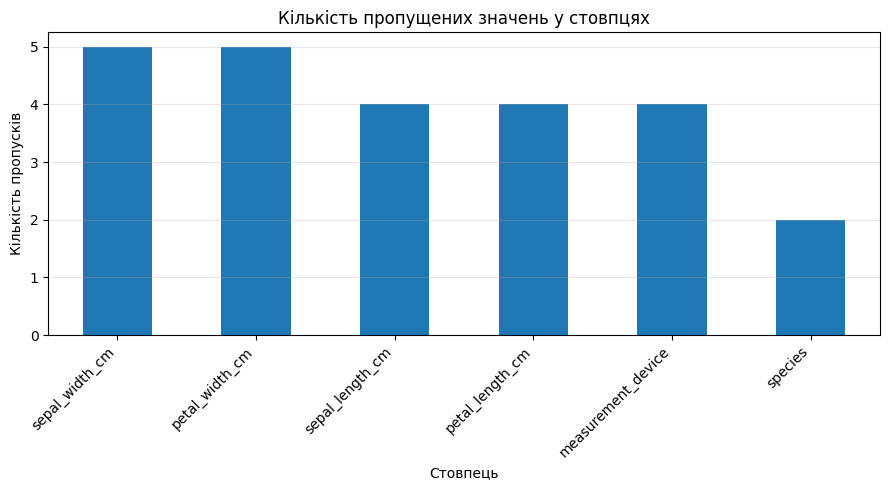

In [11]:
missing_report["missing_count"].plot(kind="bar", figsize=(9, 5))
plt.title("Кількість пропущених значень у стовпцях")
plt.xlabel("Стовпець")
plt.ylabel("Кількість пропусків")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Відповіді на питання**

1. Найбільше пропусків мають `sepal_width_cm` та `petal_width_cm` (по 5 за планом, у таблиці вище може бути трохи більше через дублікати).
2. Частка пропусків невелика (кілька відсотків на стовпець), тож вона не критична.
3. Для числових ознак доцільна **медіана**: вона стійка до викидів.
4. Для категоріальної ознаки доцільна **мода** (найчастіша категорія).
5. Пропуски цільової змінної не заповнюють модою, бо це означало б штучно призначити клас без надійної інформації; такі об'єкти видаляють.

## 7. Аналіз дублікатів

In [12]:
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_count = raw_df.duplicated().sum()

print("Кількість додаткових дублікатів:", duplicate_count)
print("Кількість рядків, які входять до груп дублікатів:", duplicate_mask.sum())

Кількість додаткових дублікатів: 4
Кількість рядків, які входять до груп дублікатів: 8


In [13]:
duplicates_table = raw_df.loc[duplicate_mask].sort_values(by=list(raw_df.columns))
display(duplicates_table)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
6,4.6,3.4,1.4,0.3,setosa,device_c
150,4.6,3.4,1.4,0.3,setosa,device_c
27,5.2,3.5,1.5,0.2,setosa,device_a
151,5.2,3.5,1.5,0.2,setosa,device_a
88,5.6,3.0,4.1,1.3,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a
50,7.0,3.2,4.7,1.4,versicolor,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a


`keep=False` позначає **всі** рядки груп дублікатів, включно з першим входженням, а `raw_df.duplicated().sum()` рахує лише **зайві** повтори.

## 8. Аналіз неправильних типів даних

In [14]:
numeric_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

print(raw_df[numeric_columns].dtypes)

sepal_length_cm     object
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
dtype: object


In [15]:
sepal_length_text = (
    raw_df["sepal_length_cm"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False)
)

sepal_length_numeric = pd.to_numeric(sepal_length_text, errors="coerce")

invalid_numeric_mask = sepal_length_text.notna() & sepal_length_numeric.isna()
invalid_numeric_values = raw_df.loc[invalid_numeric_mask, ["sepal_length_cm"]]
display(invalid_numeric_values)

,sepal_length_cm
25,unknown


In [16]:
invalid_numeric_summary = []

for column in numeric_columns:
    prepared_text = (
        raw_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    converted_values = pd.to_numeric(prepared_text, errors="coerce")
    invalid_mask = prepared_text.notna() & converted_values.isna()

    invalid_numeric_summary.append(
        {
            "column": column,
            "invalid_count": int(invalid_mask.sum()),
            "invalid_values": raw_df.loc[invalid_mask, column].astype(str).tolist()
        }
    )

invalid_numeric_summary_df = pd.DataFrame(invalid_numeric_summary)
display(invalid_numeric_summary_df)

,column,invalid_count,invalid_values
0,sepal_length_cm,1,[unknown]
1,sepal_width_cm,0,[]
2,petal_length_cm,0,[]
3,petal_width_cm,0,[]


## 9. Аналіз категоріальної ознаки

In [17]:
print("Початкові варіанти measurement_device:")
for value in raw_df["measurement_device"].dropna().unique():
    print(repr(value))

Початкові варіанти measurement_device:
'device_c'
'device_b'
'device_a'
' Device_A '
'DEVICE_B'
'device c'


In [18]:
device_counts_raw = raw_df["measurement_device"].value_counts(dropna=False)
display(device_counts_raw.rename("count").to_frame())

,count
measurement_device,
device_b,58
device_a,57
device_c,32
NaN,4
Device_A,1
DEVICE_B,1
device c,1


Записи `device_a` і `Device_A` сприймаються як різні категорії, бо порівняння рядків у pandas чутливе до регістру та пробілів. Функція `repr()` допомагає побачити зайві пробіли.

## 10. Створення робочої копії
Початкову таблицю `raw_df` не змінюємо: це дає змогу порівнювати стан до і після очищення та повторювати експерименти.

In [19]:
clean_df = raw_df.copy()

## 11. Видалення дублікатів

In [20]:
rows_before_duplicates = len(clean_df)

clean_df = clean_df.drop_duplicates().copy()

rows_after_duplicates = len(clean_df)
removed_duplicates = rows_before_duplicates - rows_after_duplicates

print("Рядків до видалення:", rows_before_duplicates)
print("Рядків після видалення:", rows_after_duplicates)
print("Видалено дублікатів:", removed_duplicates)

clean_df = clean_df.reset_index(drop=True)

Рядків до видалення: 154
Рядків після видалення: 150
Видалено дублікатів: 4


## 12. Виправлення типів числових даних

In [21]:
for column in numeric_columns:
    prepared_text = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    clean_df[column] = pd.to_numeric(prepared_text, errors="coerce")

print(clean_df[numeric_columns].dtypes)

sepal_length_cm    Float64
sepal_width_cm     Float64
petal_length_cm    Float64
petal_width_cm     Float64
dtype: object


## 13. Стандартизація категоріальних значень

In [22]:
clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(clean_df["measurement_device"].dropna().value_counts())

measurement_device
device_b    59
device_a    55
device_c    32
Name: count, dtype: Int64


In [23]:
clean_df["species"] = (
    clean_df["species"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_species = {"setosa", "versicolor", "virginica"}

invalid_species_mask = (
    clean_df["species"].notna()
    & ~clean_df["species"].isin(valid_species)
)
print("Кількість невідомих значень species:", invalid_species_mask.sum())

clean_df.loc[invalid_species_mask, "species"] = pd.NA

Кількість невідомих значень species: 0


## 14. Обробка пропусків цільової змінної

In [24]:
missing_target_count = int(clean_df["species"].isna().sum())
print("Кількість об'єктів без цільової змінної:", missing_target_count)

clean_df = clean_df.dropna(subset=["species"]).copy()
clean_df = clean_df.reset_index(drop=True)

Кількість об'єктів без цільової змінної: 2


Цільову змінну не заповнюють модою, оскільки це означало б штучно призначити квітці клас без надійної інформації.

## 15. Виявлення аномальних значень

In [25]:
def extreme_outlier_mask(series, factor=3.0):
    """
    Повертає логічну маску значень, які лежать за межами
    Q1 - factor * IQR та Q3 + factor * IQR.
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - factor * iqr
    upper_bound = q3 + factor * iqr

    mask = (series < lower_bound) | (series > upper_bound)
    return mask, lower_bound, upper_bound

In [26]:
anomaly_report_rows = []
anomaly_masks = {}

for column in numeric_columns:
    statistical_mask, lower_bound, upper_bound = extreme_outlier_mask(
        clean_df[column], factor=3.0
    )
    impossible_mask = clean_df[column] <= 0
    combined_mask = statistical_mask | impossible_mask

    anomaly_masks[column] = combined_mask

    anomaly_report_rows.append(
        {
            "column": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "impossible_count": int(impossible_mask.sum()),
            "extreme_count": int(statistical_mask.sum()),
            "total_flagged": int(combined_mask.sum())
        }
    )

anomaly_report = pd.DataFrame(anomaly_report_rows)
display(anomaly_report)

,column,lower_bound,upper_bound,impossible_count,extreme_count,total_flagged
0,sepal_length_cm,1.20,10.3,0,0,0
1,sepal_width_cm,1.15,5.0,0,1,1
2,petal_length_cm,-9.30,15.9,1,0,1
3,petal_width_cm,-4.20,6.3,0,1,1


In [27]:
for column, mask in anomaly_masks.items():
    if mask.any():
        print(f"\nАномальні значення у {column}:")
        display(clean_df.loc[mask, [column, "species"]])


Аномальні значення у sepal_width_cm:


,sepal_width_cm,species
55,18.0,versicolor



Аномальні значення у petal_length_cm:


,petal_length_cm,species
10,-1.0,setosa



Аномальні значення у petal_width_cm:


,petal_width_cm,species
119,9.5,virginica


**Пояснення**

1. Значення `-1.0` фізично неможливе: довжина частини квітки не може бути від'ємною.
2. Значення `18.0` см (ширина чашолистка) і `9.5` см (ширина пелюстки) на порядок перевищують типові для Iris (кілька сантиметрів) — найімовірніше, це помилка введення або інші одиниці вимірювання.
3. Не всі значення поза межами `1.5·IQR` є помилками: серед них можуть бути реальні рідкісні спостереження, тому їх не слід видаляти автоматично.
4. Коефіцієнт `3.0` — суворіший за стандартний `1.5`: він відсіює лише дуже нетипові значення й не видаляє звичайні природні відмінності між квітками.

## 16. Обробка аномальних значень
Замість видалення всього рядка аномальне значення замінюється на пропуск.

In [28]:
anomaly_counts = {}

for column, mask in anomaly_masks.items():
    anomaly_counts[column] = int(mask.sum())
    clean_df.loc[mask, column] = np.nan

print("Кількість аномалій за стовпцями:", anomaly_counts)

missing_before_imputation = clean_df.isna().sum()
display(missing_before_imputation.rename("missing_count").to_frame())

Кількість аномалій за стовпцями: {'sepal_length_cm': 0, 'sepal_width_cm': 1, 'petal_length_cm': 1, 'petal_width_cm': 1}


,missing_count
sepal_length_cm,5
sepal_width_cm,6
petal_length_cm,5
petal_width_cm,6
species,0
measurement_device,4


## 17. Заповнення пропусків

In [29]:
numeric_medians = clean_df[numeric_columns].median()
display(numeric_medians.rename("median").to_frame())

clean_df[numeric_columns] = clean_df[numeric_columns].fillna(numeric_medians)

,median
sepal_length_cm,5.8
sepal_width_cm,3.0
petal_length_cm,4.3
petal_width_cm,1.3


In [30]:
device_mode = clean_df["measurement_device"].mode().iloc[0]
print("Найчастіше значення measurement_device:", device_mode)

clean_df["measurement_device"] = clean_df["measurement_device"].fillna(device_mode)

Найчастіше значення measurement_device: device_b


In [31]:
print("Кількість пропусків після обробки:")
print(clean_df.isna().sum())
print("Загальна кількість пропусків:", clean_df.isna().sum().sum())

Кількість пропусків після обробки:
sepal_length_cm       0
sepal_width_cm        0
petal_length_cm       0
petal_width_cm        0
species               0
measurement_device    0
dtype: int64
Загальна кількість пропусків: 0


## 18. Повторна перевірка дублікатів
Після уніфікації типів і категорій деякі рядки можуть стати однаковими.

In [32]:
duplicates_after_cleaning = clean_df.duplicated().sum()
print("Дублікатів після очищення:", duplicates_after_cleaning)

clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Дублікатів після остаточного видалення:", clean_df.duplicated().sum())

Дублікатів після очищення: 0
Дублікатів після остаточного видалення: 0


## 19. Підсумковий аудит очищеної таблиці

In [33]:
clean_quality_report = pd.DataFrame(
    {
        "data_type": clean_df.dtypes.astype(str),
        "missing_count": clean_df.isna().sum(),
        "unique_count": clean_df.nunique()
    }
)
display(clean_quality_report)
display(clean_df.head(10))
print("Розмір очищеної таблиці:", clean_df.shape)

,data_type,missing_count,unique_count
sepal_length_cm,Float64,0,35
sepal_width_cm,Float64,0,23
petal_length_cm,Float64,0,42
petal_width_cm,Float64,0,22
species,string,0,3
measurement_device,string,0,3


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,1.3,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,device_a
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


Розмір очищеної таблиці: (148, 6)


## 20. Дослідницький аналіз очищених даних
Після завершення очищення аналізуються розподіли ознак, баланс класів, взаємозв'язки між характеристиками та кореляції.

In [34]:
display(clean_df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,148.0,5.850676,0.797402,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,148.0,3.050676,0.424023,2.0,2.8,3.0,3.3,4.4
petal_length_cm,148.0,3.731081,1.739843,1.0,1.6,4.3,5.025,6.9
petal_width_cm,148.0,1.197973,0.738952,0.1,0.3,1.3,1.8,2.5


Після очищення всі мінімальні значення додатні (фізично неможливих значень немає), максимуми не виходять за типові межі Iris, а середні та медіани близькі між собою. Найбільше стандартне відхилення має `petal_length_cm`.

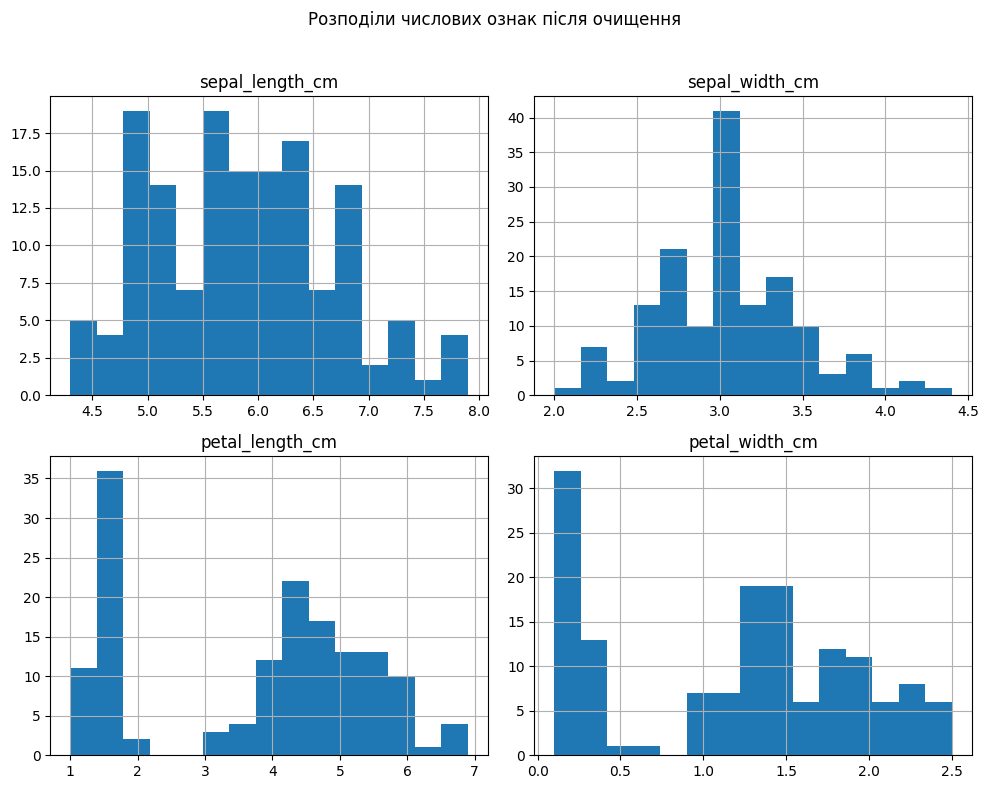

In [35]:
clean_df[numeric_columns].hist(bins=15, figsize=(10, 8))
plt.suptitle("Розподіли числових ознак після очищення")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Питання до гістограм**

1. Не всі ознаки мають симетричний розподіл: `sepal_width_cm` близька до симетричної, а `petal_length_cm` та `petal_width_cm` — бімодальні.
2. Окремі групи помітні в `petal_length_cm` і `petal_width_cm` (відповідає клас setosa і решта).
3. Найбільший діапазон має `petal_length_cm`.
4. Очевидних надзвичайних значень не залишилося.

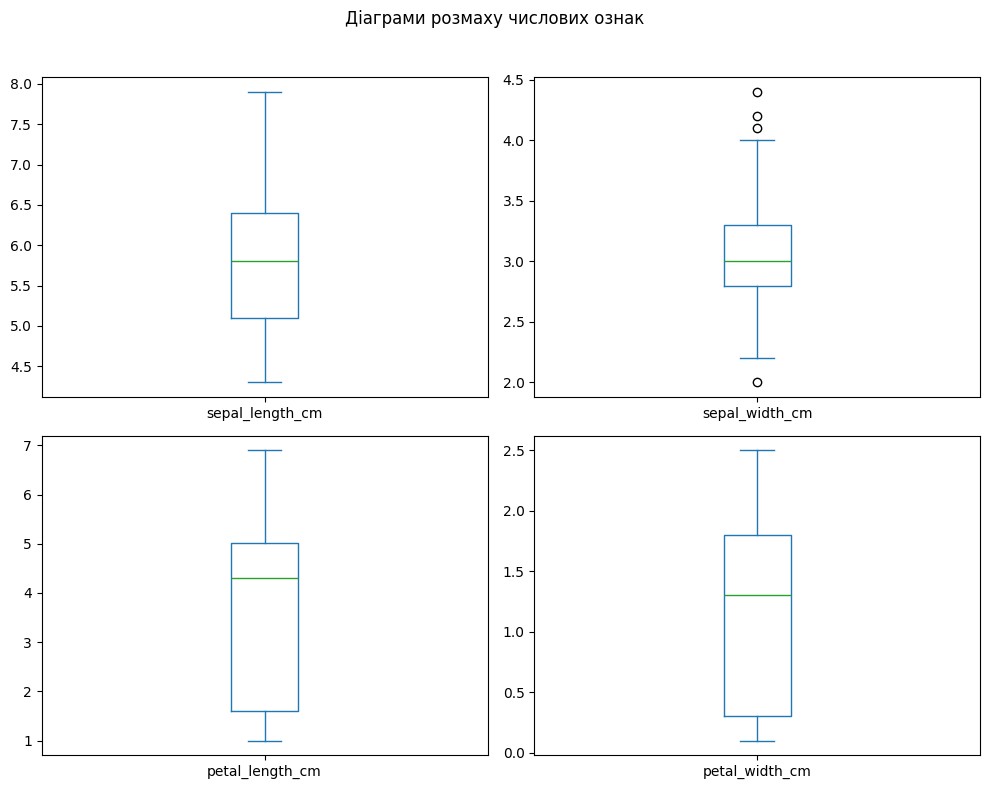

In [36]:
clean_df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 8),
    sharex=False,
    sharey=False
)
plt.suptitle("Діаграми розмаху числових ознак")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Діаграма розмаху показує медіану, перший і третій квартилі, міжквартильний розмах і потенційно віддалені значення. Точка за межами «вусів» не завжди означає помилку — це може бути реальне рідкісне спостереження.

## 21. Аналіз розподілу класів

In [37]:
class_distribution = pd.DataFrame(
    {
        "count": clean_df["species"].value_counts().sort_index(),
        "percent": (
            clean_df["species"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
display(class_distribution)

,count,percent
species,,
setosa,50,33.78
versicolor,49,33.11
virginica,49,33.11


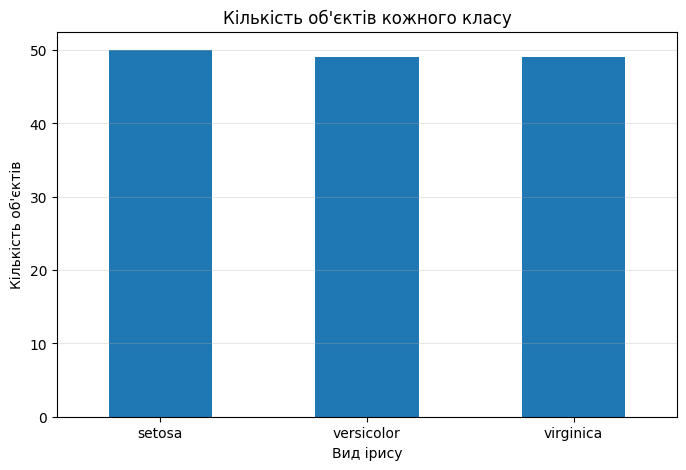

In [38]:
class_distribution["count"].plot(kind="bar", figsize=(8, 5))
plt.title("Кількість об'єктів кожного класу")
plt.xlabel("Вид ірису")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Набір залишається майже збалансованим: усі три класи представлені приблизно порівну, видалення кількох рядків без класу та дублікатів суттєво не змінило баланс.

## 22. Аналіз взаємозв'язків між ознаками

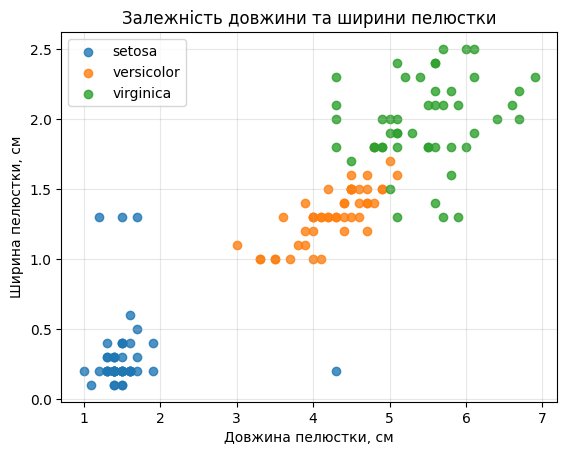

In [39]:
for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["petal_length_cm"],
        group["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини пелюстки")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

1. Найкраще відокремлюється **setosa**.
2. Частково перекриваються **versicolor** і **virginica**.
3. Так, ці ознаки добре підходять для класифікації.
4. Залежність між довжиною та шириною пелюстки — близька до лінійної, додатна.

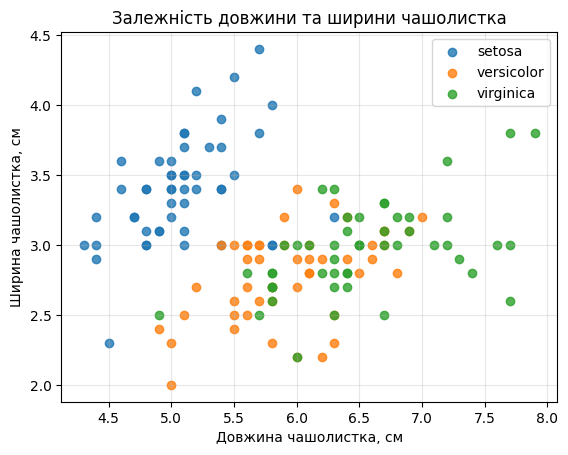

In [40]:
for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["sepal_length_cm"],
        group["sepal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини чашолистка")
plt.xlabel("Довжина чашолистка, см")
plt.ylabel("Ширина чашолистка, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Ознаки чашолистка розділяють класи гірше, ніж ознаки пелюстки: versicolor і virginica значно перекриваються, setosa відокремлюється лише частково.

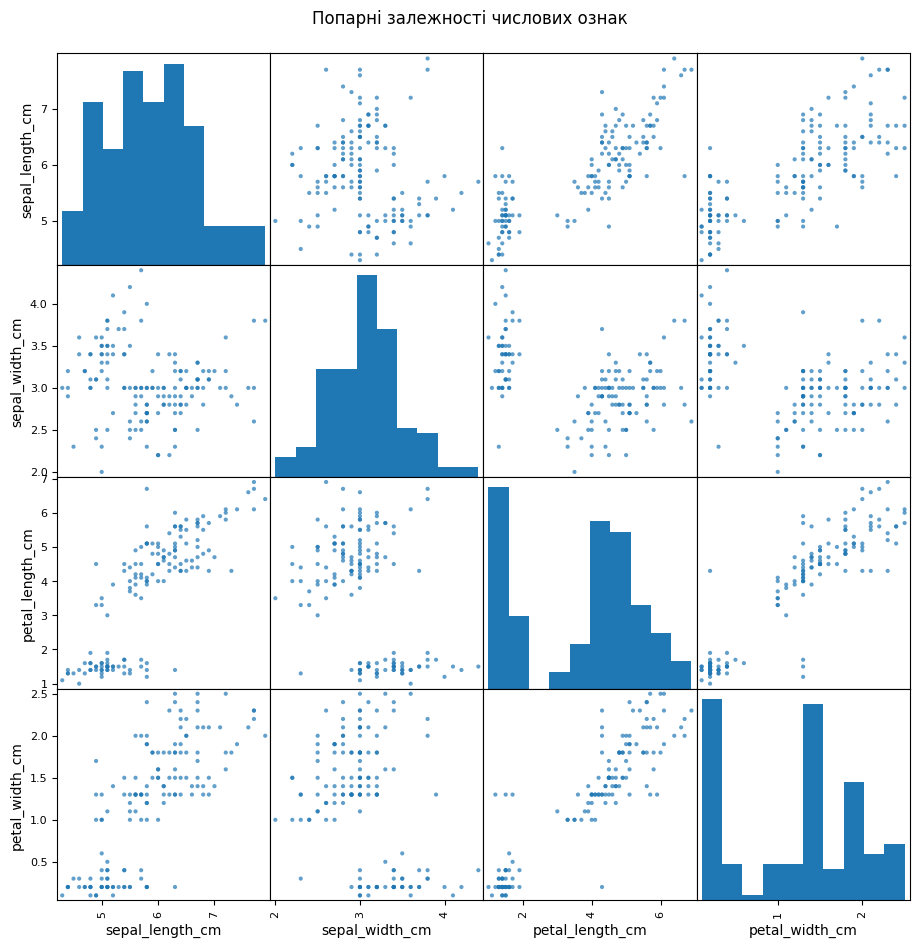

In [41]:
pd.plotting.scatter_matrix(
    clean_df[numeric_columns],
    figsize=(11, 11),
    diagonal="hist",
    alpha=0.7
)
plt.suptitle("Попарні залежності числових ознак", y=0.92)
plt.show()

## 23. Матриця кореляцій

In [42]:
correlation_matrix = clean_df[numeric_columns].corr()
display(correlation_matrix.round(3))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000,-0.105,0.819,0.760
sepal_width_cm,-0.105,1.000,-0.403,-0.355
petal_length_cm,0.819,-0.403,1.000,0.917
petal_width_cm,0.760,-0.355,0.917,1.000


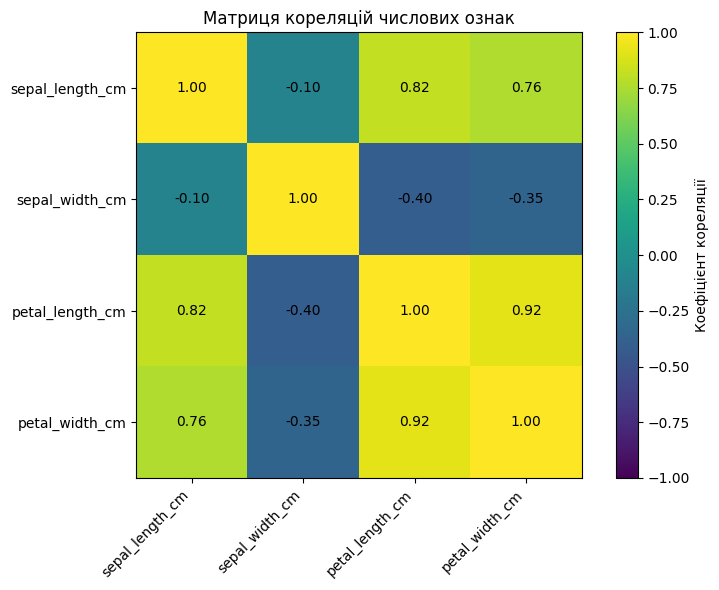

In [43]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(correlation_matrix, vmin=-1, vmax=1)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for row_index in range(len(numeric_columns)):
    for column_index in range(len(numeric_columns)):
        ax.text(
            column_index,
            row_index,
            f"{correlation_matrix.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(image, ax=ax, label="Коефіцієнт кореляції")
ax.set_title("Матриця кореляцій числових ознак")
plt.tight_layout()
plt.show()

1. Найсильніша додатна кореляція — між `petal_length_cm` і `petal_width_cm` (близько 0.92).
2. Найслабше корелює `sepal_width_cm` з іншими ознаками (вона навіть має слабку від'ємну кореляцію).
3. Кореляція, близька до 1, означає майже лінійний прямий зв'язок: коли росте одна ознака, росте й інша.
4. Кореляція **не доводить** причинно-наслідкового зв'язку.
5. Сильна кореляція між ознаками (мультиколінеарність) робить оцінки коефіцієнтів лінійних моделей нестійкими та ускладнює їх інтерпретацію.

## 24. Аналіз категоріальної ознаки

In [44]:
device_distribution = pd.DataFrame(
    {
        "count": clean_df["measurement_device"].value_counts().sort_index(),
        "percent": (
            clean_df["measurement_device"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
display(device_distribution)

,count,percent
measurement_device,,
device_a,55,37.16
device_b,61,41.22
device_c,32,21.62


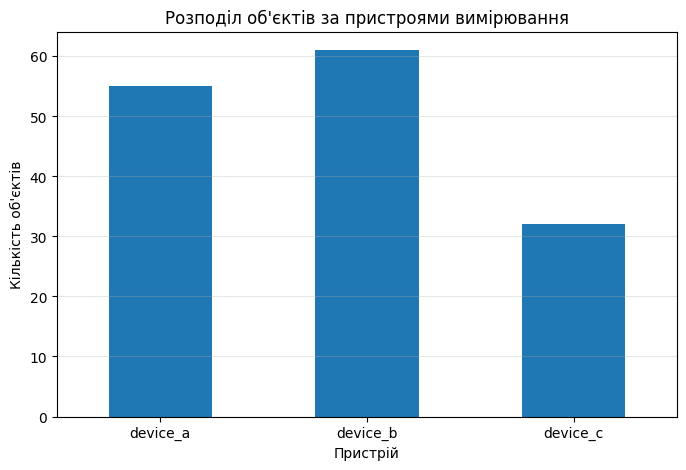

In [45]:
device_distribution["count"].plot(kind="bar", figsize=(8, 5))
plt.title("Розподіл об'єктів за пристроями вимірювання")
plt.xlabel("Пристрій")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 25. Кодування категоріальних ознак
Категоріальна ознака `measurement_device` кодується методом one-hot. Цільова змінна `species` перетворюється на числові коди.

In [46]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["measurement_device"],
    dtype=int
)
display(encoded_df.head())

print("Стовпці після кодування:")
for column in encoded_df.columns:
    print("-", column)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,setosa,0,0,1
1,5.8,3.0,1.4,0.2,setosa,0,1,0
2,4.7,3.2,1.3,0.2,setosa,0,0,1
3,5.1,3.1,1.5,0.2,setosa,0,1,0
4,5.0,3.6,1.4,0.2,setosa,1,0,0


Стовпці після кодування:
- sepal_length_cm
- sepal_width_cm
- petal_length_cm
- petal_width_cm
- species
- measurement_device_device_a
- measurement_device_device_b
- measurement_device_device_c


In [47]:
class_mapping = {"setosa": 0, "versicolor": 1, "virginica": 2}

encoded_df["species_code"] = encoded_df["species"].map(class_mapping).astype(int)

display(
    encoded_df[["species", "species_code"]]
    .drop_duplicates()
    .sort_values("species_code")
)

,species,species_code
0,setosa,0
50,versicolor,1
99,virginica,2


## 26. Розділення ознак і цільової змінної

In [48]:
X = encoded_df.drop(columns=["species", "species_code"])
y = encoded_df["species_code"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
display(X.head())
display(y.head())

Розмір X: (148, 7)
Розмір y: (148,)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


,species_code
0,0
1,0
2,0
3,0
4,0


Зі складу `X` видалено і `species`, і `species_code`: обидва стовпці містять правильний клас, тому їх використання як вхідної ознаки спричинило б прямий **витік цільової інформації**.

## 27. Формування навчальної й тестової вибірок
Для тестування виділяється 20 % об'єктів. Використовується стратифікація, щоб зберегти приблизно однакові частки класів.

**Примітка.** У межах цієї практичної роботи поділ виконується після очищення всього набору даних. Отримані `X_train` і `X_test` призначені для демонстрації структури вибірок, збереження співвідношення класів і підготовки файлів для наступної роботи. На цьому етапі `X_test` ще не слід використовувати для остаточної незалежної оцінки якості моделі, оскільки параметри очищення та заповнення пропусків було визначено до розбиття даних.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


- `test_size=0.20` — приблизно 20 % об'єктів потрапляє до тестової вибірки.
- `random_state=42` — відтворюваність розбиття.
- `stratify=y` — збереження співвідношення класів.

## 28. Порівняння розподілів класів

In [50]:
reverse_class_mapping = {value: key for key, value in class_mapping.items()}

train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

class_split_report = pd.DataFrame(
    {"train_count": train_counts, "test_count": test_counts}
)
class_split_report.index = [
    reverse_class_mapping[index] for index in class_split_report.index
]

class_split_report["train_percent"] = (
    class_split_report["train_count"] / class_split_report["train_count"].sum() * 100
).round(2)
class_split_report["test_percent"] = (
    class_split_report["test_count"] / class_split_report["test_count"].sum() * 100
).round(2)

display(class_split_report)

,train_count,test_count,train_percent,test_percent
setosa,40,10,33.90,33.33
versicolor,39,10,33.05,33.33
virginica,39,10,33.05,33.33


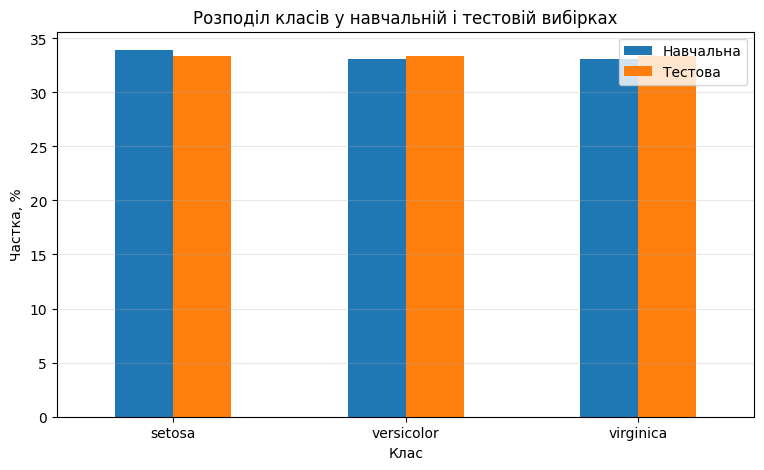

In [51]:
class_split_report[["train_percent", "test_percent"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Розподіл класів у навчальній і тестовій вибірках")
plt.xlabel("Клас")
plt.ylabel("Частка, %")
plt.xticks(rotation=0)
plt.legend(["Навчальна", "Тестова"])
plt.grid(axis="y", alpha=0.3)
plt.show()

1. Кожен клас представлений у train.
2. Кожен клас представлений у test.
3. Частки класів у train і test дуже близькі.
4. Параметр `stratify=y` гарантує збереження співвідношення класів в обох вибірках.

## 29. Порівняння зі звичайним розбиттям
Цей етап виконується лише для демонстрації.

In [52]:
_, _, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7
)

random_split_report = pd.DataFrame(
    {
        "train_percent": y_train_random.value_counts(normalize=True).sort_index().mul(100).round(2),
        "test_percent": y_test_random.value_counts(normalize=True).sort_index().mul(100).round(2)
    }
)
random_split_report.index = [
    reverse_class_mapping[index] for index in random_split_report.index
]

display(random_split_report)

,train_percent,test_percent
setosa,36.44,23.33
versicolor,31.36,40.00
virginica,32.20,36.67


Без стратифікації частки класів у test помітніше відхиляються від часток у train, ніж у стратифікованому розбитті. У наступних роботах випадкове розбиття без стратифікації використовувати не потрібно.

## 30. Формування звіту про очищення

In [53]:
preprocessing_summary = pd.DataFrame(
    [
        {
            "stage": "Початковий пошкоджений набір",
            "row_count": len(raw_df),
            "missing_count": int(raw_df.isna().sum().sum()),
            "duplicate_count": int(raw_df.duplicated().sum())
        },
        {
            "stage": "Після видалення дублікатів",
            "row_count": rows_after_duplicates,
            "missing_count": None,
            "duplicate_count": 0
        },
        {
            "stage": "Після очищення",
            "row_count": len(clean_df),
            "missing_count": int(clean_df.isna().sum().sum()),
            "duplicate_count": int(clean_df.duplicated().sum())
        },
        {
            "stage": "Навчальна вибірка",
            "row_count": len(X_train),
            "missing_count": int(X_train.isna().sum().sum()),
            "duplicate_count": int(X_train.duplicated().sum())
        },
        {
            "stage": "Тестова вибірка",
            "row_count": len(X_test),
            "missing_count": int(X_test.isna().sum().sum()),
            "duplicate_count": int(X_test.duplicated().sum())
        }
    ]
)
display(preprocessing_summary)

,stage,row_count,missing_count,duplicate_count
0,Початковий пошкоджений набір,154,24.0,4
1,Після видалення дублікатів,150,NaN,0
2,Після очищення,148,0.0,0
3,Навчальна вибірка,118,0.0,0
4,Тестова вибірка,30,0.0,0


## 31. Збереження підготовлених даних

In [54]:
clean_df.to_csv(CLEANED_PATH, index=False)
print("Очищений набір збережено:", CLEANED_PATH)

X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)

y_train.rename("species_code").to_csv(Y_TRAIN_PATH, index=False)
y_test.rename("species_code").to_csv(Y_TEST_PATH, index=False)

preprocessing_summary.to_csv(SUMMARY_PATH, index=False)
print("Звіт збережено:", SUMMARY_PATH)

with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, ensure_ascii=False, indent=4)
print("Словник класів збережено:", CLASS_MAPPING_PATH)

Очищений набір збережено: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Звіт збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/preprocessing_summary.csv
Словник класів збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/class_mapping.json


In [55]:
output_files = [
    DIRTY_PATH,
    CLEANED_PATH,
    X_TRAIN_PATH,
    X_TEST_PATH,
    Y_TRAIN_PATH,
    Y_TEST_PATH,
    SUMMARY_PATH,
    CLASS_MAPPING_PATH
]

for path in output_files:
    print(path.name, "–", "створено" if path.exists() else "відсутній")

iris_dirty.csv – створено
iris_cleaned.csv – створено
X_train.csv – створено
X_test.csv – створено
y_train.csv – створено
y_test.csv – створено
preprocessing_summary.csv – створено
class_mapping.json – створено


## 32. Автоматична перевірка результатів

In [56]:
assert clean_df.isna().sum().sum() == 0, "В очищеній таблиці залишилися пропуски."
assert clean_df.duplicated().sum() == 0, "В очищеній таблиці залишилися дублікати."

assert set(clean_df["species"].unique()) == {
    "setosa", "versicolor", "virginica"
}, "Набір класів не відповідає очікуваному."

assert set(clean_df["measurement_device"].unique()) == {
    "device_a", "device_b", "device_c"
}, "Категорії пристроїв очищено неправильно."

assert all(
    pd.api.types.is_numeric_dtype(clean_df[column])
    for column in numeric_columns
), "Не всі числові стовпці мають числовий тип."

assert (clean_df[numeric_columns] > 0).all().all(), (
    "Залишилися фізично неможливі значення."
)

assert len(X_train) + len(X_test) == len(X), (
    "Кількість об'єктів після розбиття змінилася."
)
assert list(X_train.columns) == list(X_test.columns), (
    "Стовпці train і test не збігаються."
)
assert set(y_train.unique()) == {0, 1, 2}, (
    "У навчальній вибірці відсутній один із класів."
)
assert set(y_test.unique()) == {0, 1, 2}, (
    "У тестовій вибірці відсутній один із класів."
)
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Усі основні перевірки виконано успішно.")

Усі основні перевірки виконано успішно.


## Додаткове завдання (варіант 1): функція аудиту даних

In [57]:
def data_quality_summary(dataset):
    """
    Повертає таблицю з типами даних, кількістю пропусків,
    відсотком пропусків, кількістю унікальних значень
    і кількістю дублікатів.
    """
    summary = pd.DataFrame(
        {
            "data_type": dataset.dtypes.astype(str),
            "missing_count": dataset.isna().sum(),
            "missing_percent": dataset.isna().mean().mul(100).round(2),
            "unique_count": dataset.nunique()
        }
    )
    print("Кількість повних дублікатів:", dataset.duplicated().sum())
    return summary


display(data_quality_summary(raw_df))
display(data_quality_summary(clean_df))

Кількість повних дублікатів: 4


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


Кількість повних дублікатів: 0


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,Float64,0,0.0,35
sepal_width_cm,Float64,0,0.0,23
petal_length_cm,Float64,0,0.0,42
petal_width_cm,Float64,0,0.0,22
species,string,0,0.0,3
measurement_device,string,0,0.0,3


# Висновки
Нижче підсумок формується автоматично з фактичних результатів виконання комірок.

In [58]:
corr_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
    )
    .stack()
    .sort_values(ascending=False)
)
best_pair = corr_pairs.index[0]
best_corr = corr_pairs.iloc[0]

class_pct = class_distribution["percent"].round(1).to_dict()
split_pct = class_split_report[["train_percent", "test_percent"]].round(1).to_dict("index")

display(Markdown(f"""
Під час виконання практичної роботи було проведено дослідницький аналіз і підготовку набору даних Iris до навчання моделей машинного навчання.

Для відпрацювання методів очищення було створено контрольовано пошкоджену версію набору (**{len(raw_df)}** рядків), яка містила пропущені значення, дублікати, текстові записи у числовому стовпці, неузгоджені назви категорій і аномальні числові значення.

Під час аудиту визначено типи даних, кількість пропусків, кількість унікальних значень і повні дублікати. Числові стовпці перетворено до правильних типів, а некоректні текстові записи (наприклад, `unknown`) — на пропущені значення. Назви категорій пристроїв уніфіковано до трьох: `device_a`, `device_b`, `device_c`.

**Ключові числа:**
- видалено повних дублікатів на першому етапі: **{removed_duplicates}**;
- видалено рядків без цільової змінної: **{missing_target_count}**;
- знайдено аномальних значень (фізично неможливих та екстремальних за IQR, k = 3): **{sum(anomaly_counts.values())}** (за стовпцями: {anomaly_counts});
- додатково видалено дублікатів після очищення: **{int(duplicates_after_cleaning)}**;
- рядків у очищеній таблиці: **{len(clean_df)}**;
- найсильніший кореляційний зв'язок: **{best_pair[0]}** і **{best_pair[1]}** (r = {best_corr:.3f}).

Пропуски числових ознак заповнено медіанами, а пропуски категоріальної ознаки — модою (`{device_mode}`). Після очищення в таблиці не залишилося пропущених значень і повних дублікатів.

Побудовано гістограми, діаграми розмаху, діаграми залежностей між ознаками, розподіл класів і матрицю кореляцій. Довжина та ширина пелюстки мають сильний взаємозв'язок і добре відокремлюють клас setosa.

Категоріальну ознаку `measurement_device` закодовано методом one-hot, а цільову змінну `species` перетворено на числові коди (0, 1, 2). Набір розділено на матрицю ознак `X` і цільову змінну `y`.

Сформовано навчальну ({len(X_train)} об'єктів) і тестову ({len(X_test)} об'єктів) вибірки у співвідношенні 80 % / 20 %. Частки класів у наборі: {class_pct}. Завдяки стратифікованому розбиттю частки класів у train і test практично збігаються: {split_pct}. Баланс класів зберігся.

У цій роботі розбиття виконано після очищення та кодування всього набору даних як навчальне спрощення. Тому тестова вибірка демонструє принцип поділу даних і стратифікації, але ще не використовується для остаточного незалежного оцінювання моделі. У наступній практичній роботі параметри заповнення пропусків і кодування категорій визначатимуться лише за навчальною вибіркою за допомогою `Pipeline`.

Очищений набір, навчальну і тестову вибірки, словник класів та звіт про підготовку збережено для використання в наступних практичних роботах.
"""))


Під час виконання практичної роботи було проведено дослідницький аналіз і підготовку набору даних Iris до навчання моделей машинного навчання.

Для відпрацювання методів очищення було створено контрольовано пошкоджену версію набору (**154** рядків), яка містила пропущені значення, дублікати, текстові записи у числовому стовпці, неузгоджені назви категорій і аномальні числові значення.

Під час аудиту визначено типи даних, кількість пропусків, кількість унікальних значень і повні дублікати. Числові стовпці перетворено до правильних типів, а некоректні текстові записи (наприклад, `unknown`) — на пропущені значення. Назви категорій пристроїв уніфіковано до трьох: `device_a`, `device_b`, `device_c`.

**Ключові числа:**
- видалено повних дублікатів на першому етапі: **4**;
- видалено рядків без цільової змінної: **2**;
- знайдено аномальних значень (фізично неможливих та екстремальних за IQR, k = 3): **3** (за стовпцями: {'sepal_length_cm': 0, 'sepal_width_cm': 1, 'petal_length_cm': 1, 'petal_width_cm': 1});
- додатково видалено дублікатів після очищення: **0**;
- рядків у очищеній таблиці: **148**;
- найсильніший кореляційний зв'язок: **petal_length_cm** і **petal_width_cm** (r = 0.917).

Пропуски числових ознак заповнено медіанами, а пропуски категоріальної ознаки — модою (`device_b`). Після очищення в таблиці не залишилося пропущених значень і повних дублікатів.

Побудовано гістограми, діаграми розмаху, діаграми залежностей між ознаками, розподіл класів і матрицю кореляцій. Довжина та ширина пелюстки мають сильний взаємозв'язок і добре відокремлюють клас setosa.

Категоріальну ознаку `measurement_device` закодовано методом one-hot, а цільову змінну `species` перетворено на числові коди (0, 1, 2). Набір розділено на матрицю ознак `X` і цільову змінну `y`.

Сформовано навчальну (118 об'єктів) і тестову (30 об'єктів) вибірки у співвідношенні 80 % / 20 %. Частки класів у наборі: {'setosa': 33.8, 'versicolor': 33.1, 'virginica': 33.1}. Завдяки стратифікованому розбиттю частки класів у train і test практично збігаються: {'setosa': {'train_percent': 33.9, 'test_percent': 33.3}, 'versicolor': {'train_percent': 33.0, 'test_percent': 33.3}, 'virginica': {'train_percent': 33.0, 'test_percent': 33.3}}. Баланс класів зберігся.

У цій роботі розбиття виконано після очищення та кодування всього набору даних як навчальне спрощення. Тому тестова вибірка демонструє принцип поділу даних і стратифікації, але ще не використовується для остаточного незалежного оцінювання моделі. У наступній практичній роботі параметри заповнення пропусків і кодування категорій визначатимуться лише за навчальною вибіркою за допомогою `Pipeline`.

Очищений набір, навчальну і тестову вибірки, словник класів та звіт про підготовку збережено для використання в наступних практичних роботах.
